# Phase 3: Baseline Model (LFCC + XGBoost): Results

All numbers and plots here come from **real ASVspoof 2019 LA** results written by `scripts/train_baseline.py`
(`results/baseline_metrics.json`, `results/baseline_scores.npz`). **No placeholder or synthetic values are used.**
If those files are missing, the notebook stops with an error.

**Pipeline**: 4 s @ 16 kHz → 60-dim LFCC (20 static + Δ + ΔΔ) → mean/std/skew/kurtosis over time (240-dim) → StandardScaler → XGBoost (500 trees, depth 6, lr 0.05).

In [1]:
import sys, json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm
from sklearn.metrics import roc_curve, roc_auc_score
sys.path.append('..')
from src.config import config
sns.set_theme(style='darkgrid')

metrics_file = config.paths.results_dir / 'baseline_metrics.json'
scores_file = config.paths.results_dir / 'baseline_scores.npz'
if not metrics_file.exists() or not scores_file.exists():
    raise FileNotFoundError(
        'Real baseline results not found. Run on the real dataset first:\n'
        '  PYTHONPATH=. venv/bin/python scripts/train_baseline.py')
results = json.load(open(metrics_file))
S = np.load(scores_file)
print(f"Dev  EER: {results['dev_metrics']['overall_eer']:.2f}%  AUC: {results['dev_metrics']['overall_auc']:.4f}")
print(f"Eval EER: {results['eval_metrics']['overall_eer']:.2f}%  AUC: {results['eval_metrics']['overall_auc']:.4f}")

Dev  EER: 18.37%  AUC: 0.9029
Eval EER: 35.11%  AUC: 0.7162


## 1. Per-attack EER (eval set, A07–A19)

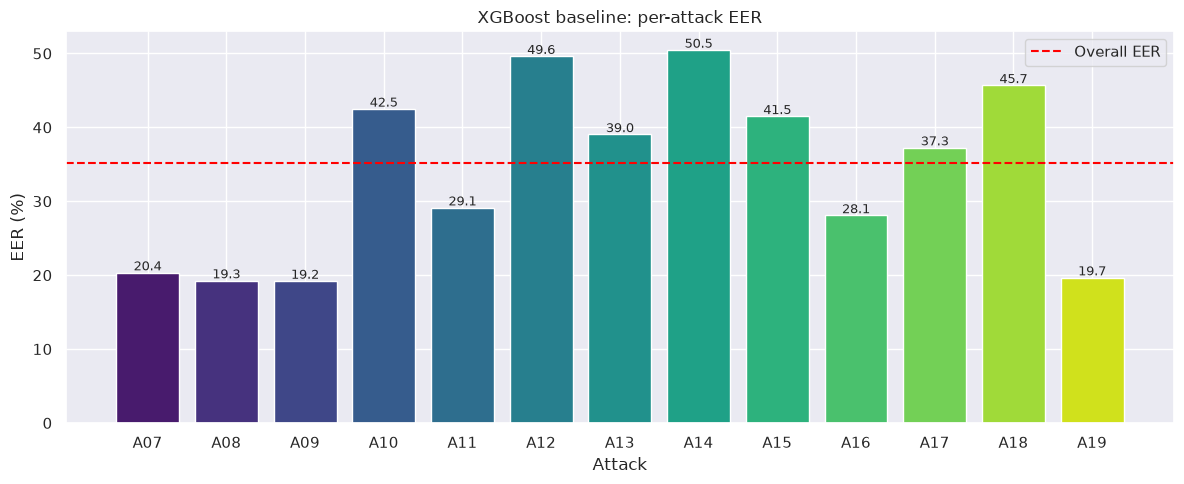

In [2]:
pa = results['eval_metrics']['per_attack_eer']
att, eer = list(pa.keys()), list(pa.values())
plt.figure(figsize=(12, 5))
bars = plt.bar(att, eer, color=sns.color_palette('viridis', len(att)))
plt.axhline(results['eval_metrics']['overall_eer'], color='red', ls='--', label='Overall EER')
for b in bars:
    plt.text(b.get_x() + b.get_width()/2, b.get_height() + 0.3, f'{b.get_height():.1f}', ha='center', fontsize=9)
plt.xlabel('Attack'); plt.ylabel('EER (%)'); plt.title('XGBoost baseline: per-attack EER'); plt.legend()
plt.tight_layout(); plt.show()

## 2. ROC and DET curves

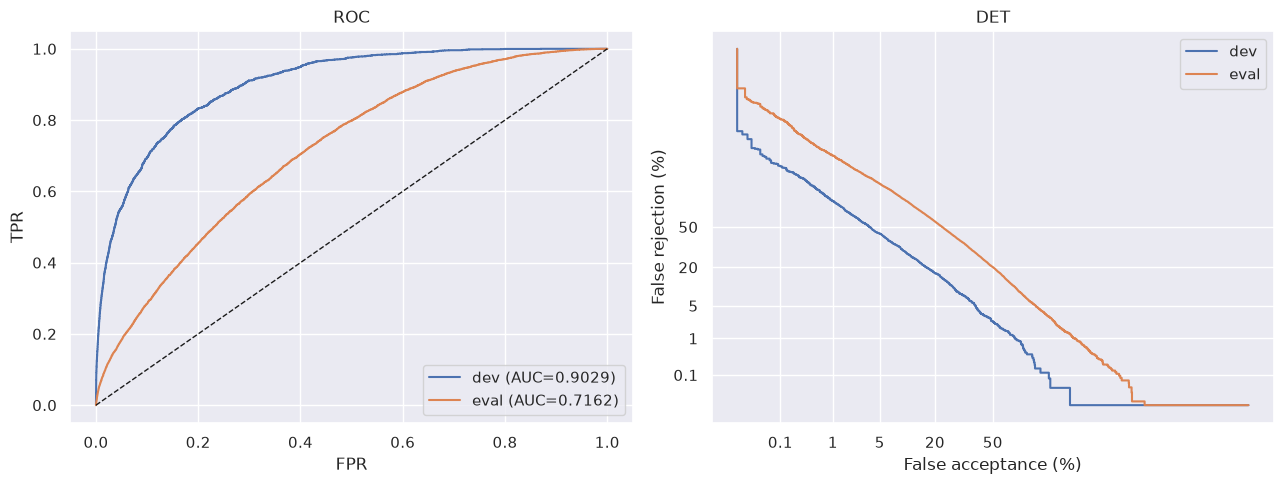

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for split in ['dev', 'eval']:
    y, s = S[f'{split}_labels'], S[f'{split}_scores']
    fpr, tpr, _ = roc_curve(y, s, pos_label=1)
    ax[0].plot(fpr, tpr, label=f'{split} (AUC={roc_auc_score(y, s):.4f})')
    fnr = 1 - tpr
    clip = lambda p: np.clip(p, 1e-4, 1 - 1e-4)
    ax[1].plot(norm.ppf(clip(fpr)), norm.ppf(clip(fnr)), label=split)
ax[0].plot([0, 1], [0, 1], 'k--', lw=1); ax[0].set_xlabel('FPR'); ax[0].set_ylabel('TPR'); ax[0].set_title('ROC'); ax[0].legend()
ticks = [0.001, 0.01, 0.05, 0.2, 0.5]
ax[1].set_xticks(norm.ppf(ticks)); ax[1].set_xticklabels([f'{t*100:g}' for t in ticks])
ax[1].set_yticks(norm.ppf(ticks)); ax[1].set_yticklabels([f'{t*100:g}' for t in ticks])
ax[1].set_xlabel('False acceptance (%)'); ax[1].set_ylabel('False rejection (%)'); ax[1].set_title('DET'); ax[1].legend()
plt.tight_layout(); plt.show()

## 3. Score distributions (eval)

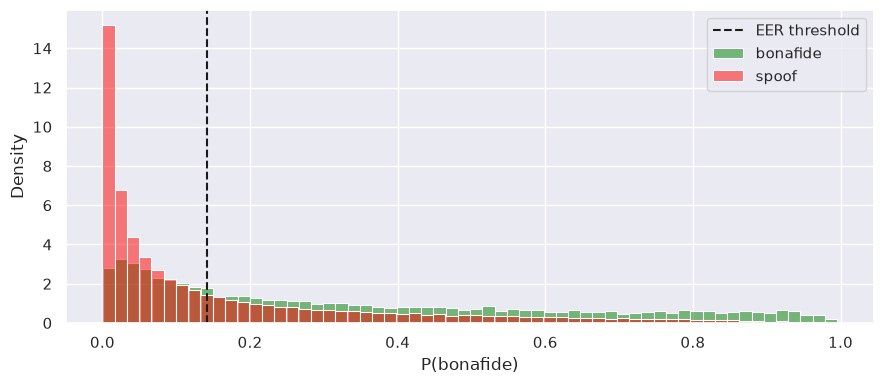

In [4]:
y, s = S['eval_labels'], S['eval_scores']
plt.figure(figsize=(9, 4))
sns.histplot(s[y == 1], bins=60, stat='density', color='green', alpha=.5, label='bonafide')
sns.histplot(s[y == 0], bins=60, stat='density', color='red', alpha=.5, label='spoof')
plt.axvline(results['eval_metrics']['threshold'], color='k', ls='--', label='EER threshold')
plt.xlabel('P(bonafide)'); plt.legend(); plt.tight_layout(); plt.show()

## 4. Analysis

_Fill in after the real run: which attacks are hardest for static statistics, and what that implies for the temporal model in Phase 4._